# Isolated EODs, one figure per frame: masks, zooms, and predicted vs recorded voltages (4-fish, Kaden masks)

The 20 example isolated EODs per fish of `EOD_isolated_examples_4fish_kaden.ipynb` (10 cm / 5×, spread over p* and videos).

Each figure:
- **tank** (left): Kaden's visible masks of the EOD's video frame, every fish in its colour with its letter; the isolated fish
  outlined; electrodes (+ filled, − open, pair number at the + pole); the isolated fish's top pair p* joined by a line.
- **zooms** (right, one per fish): a square window centred on that fish's mask, side 1.6 × the fish's length; mask at full
  resolution, the mask midline the model used (head = dot), other fish's masks in grey; 2 cm scale bar.
- **voltages** (bottom), per electrode pair, on the **first EOD phase** (each pair's trace demeaned; the opposite-sign extremum
  before the main phase on the pair with the largest |V|; all 10 pairs at that sample), as in `EOD_L2_isolated_first_peak_4fish_kaden.ipynb`:
  - left, **volts**: the recording (black) and, for every fish, its prediction if it were the emitter,
    $a_f\, b_p\, m_{f,p}$, with my model's own sign (no × −1) and the per-fish × per-pair gains fitted by least squares
    (gains ≥ 0) on the **other four videos**' isolated EODs. Legend: $\lVert r - \hat r\rVert / \max|r|$ per fish.
  - right, **shape**: the recording and each fish's model, each scaled to max |v| = 1 (signs kept). Legend: shape L2.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from model_voltages_4fish import Masks                                # imports mask_metrics, which sets the Agg backend
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
EX = f'{BASE}/fish_pair_factors_iso10cm_dom5/example_frames'
OUT = f'{EX}/per_frame'; os.makedirs(OUT, exist_ok=True)
KADEN = 'data/track_Kaden/results_{t}_full/video2024-02-20T{t}/outputs/video2024-02-20T{t}.pkl'
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv')
PIDS = [p for p, _, _ in load_electrode_pairs('data/electrodes/electrodes_signed_px_coord_4-fish.csv', P)]
PX_CM = P / 60
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}                     # 90th percentile of the mask midline (cm)
H = pd.read_csv(f'{BASE}/fish_pair_factors_threshold_grid/l2_isolated_first_peak/gains_fit_without_each_video_first_peak.csv', index_col='video')

PK = pd.read_csv(f'{EX}/example_frames_20_per_fish.csv')
masks, mids, R1, M, SHAPE_PICK, T1 = {}, {}, {}, {}, {}, {}
for t in PK.video.unique():
    g = PK[PK.video == t]
    mk = Masks(dict(identity='kaden', masks=KADEN.format(t=t)))
    for k in g.Frame.unique(): masks[(t, int(k))] = mk(int(k))
    del mk
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}
    for k in g.Frame.unique(): mids[(t, int(k))] = z['mids'][idx[int(k)]] * (P - 1)
    rows = g.row.to_numpy()
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)])
    Vt = recorded_pair_traces_all(df.iloc[rows], PIDS, 25); del df
    pv = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    pick = pd.read_csv(f'{BASE}/{t}/eod_assignments.csv', usecols=['fish | mine, shape'])['fish | mine, shape'].fillna('').to_numpy()
    for k, rw in enumerate(rows):
        w = Vt[k, np.abs(Vt[k]).max(1).argmax()]; t2 = np.abs(w).argmax(); s2 = np.sign(w[t2])
        t1 = int(np.argmax(-s2 * w[:t2])) if t2 > 0 else -1
        R1[(t, int(rw))] = Vt[k, :, t1]; T1[(t, int(rw))] = (t1, int(t2))
        M[(t, int(rw))] = -pv['mine_unit_current'][rw]                     # (4, 10), raw model sign
        SHAPE_PICK[(t, int(rw))] = pick[rw]
print(f'{len(PK)} EODs loaded')

80 EODs loaded


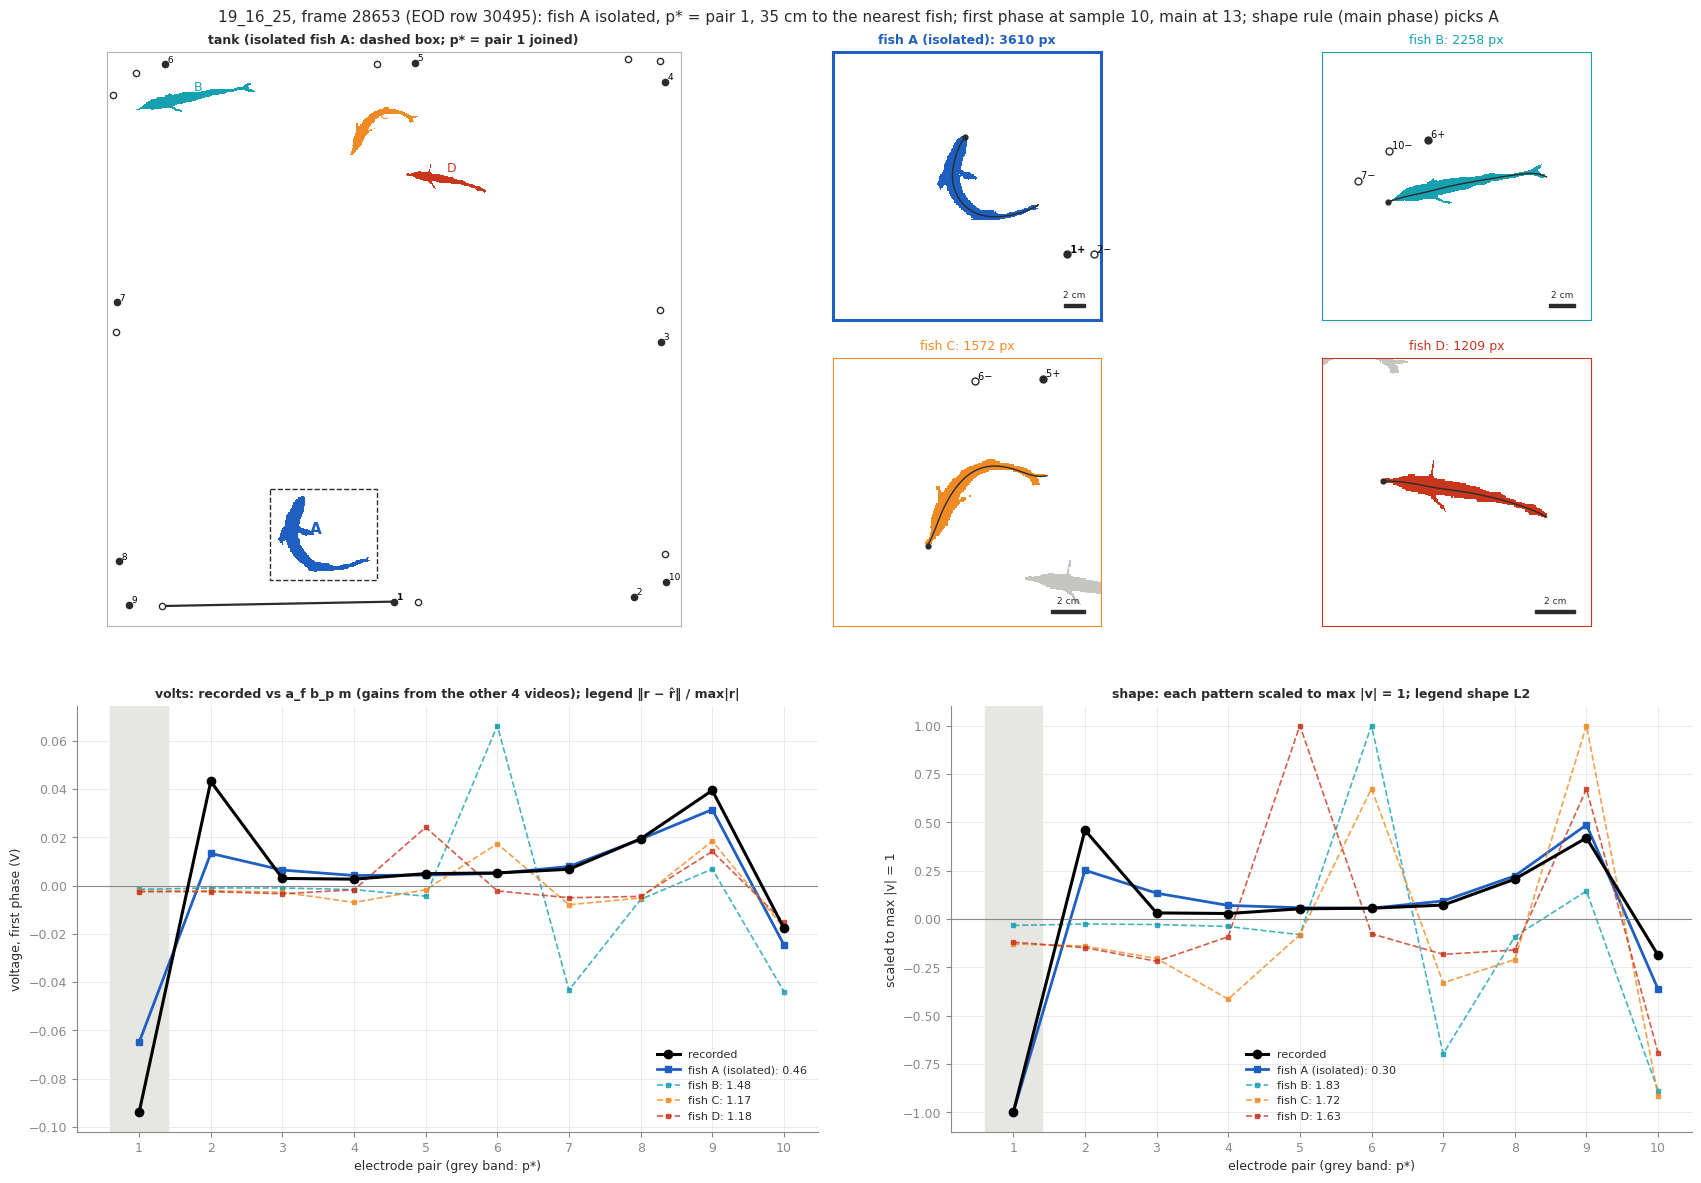

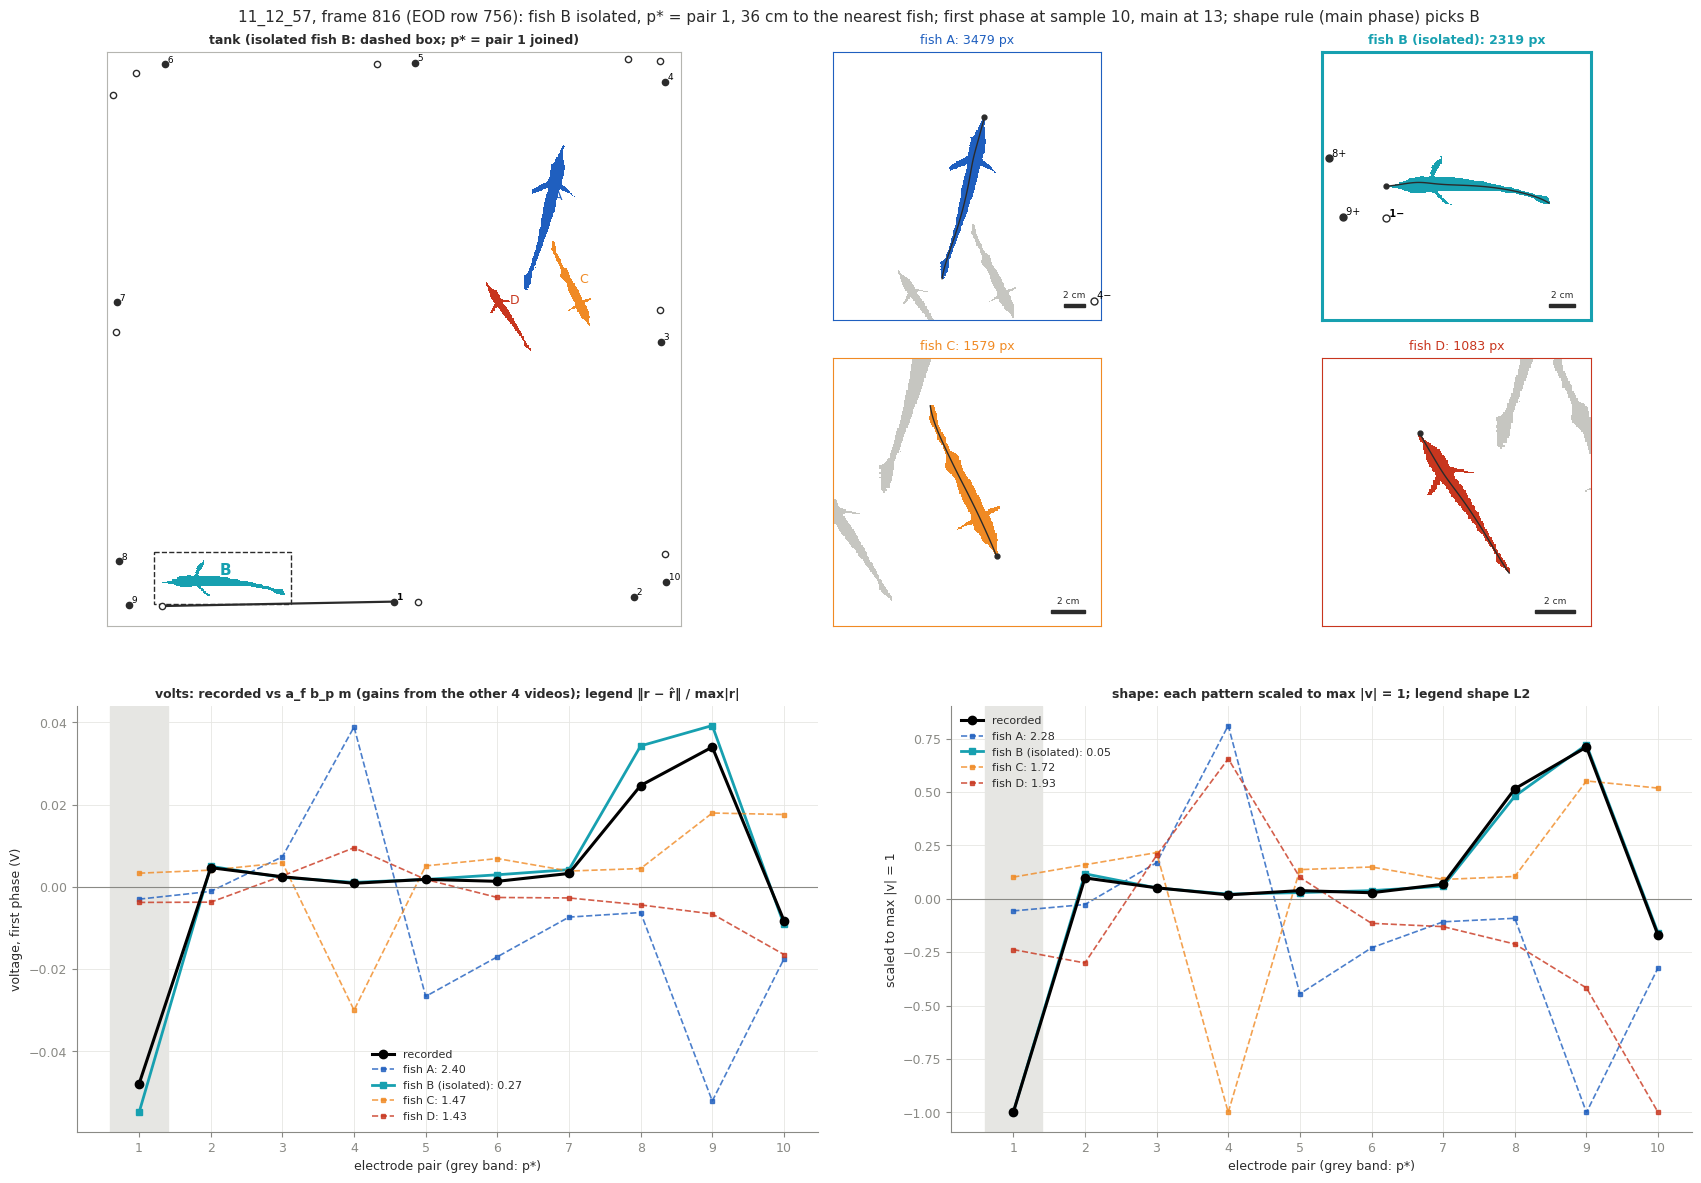

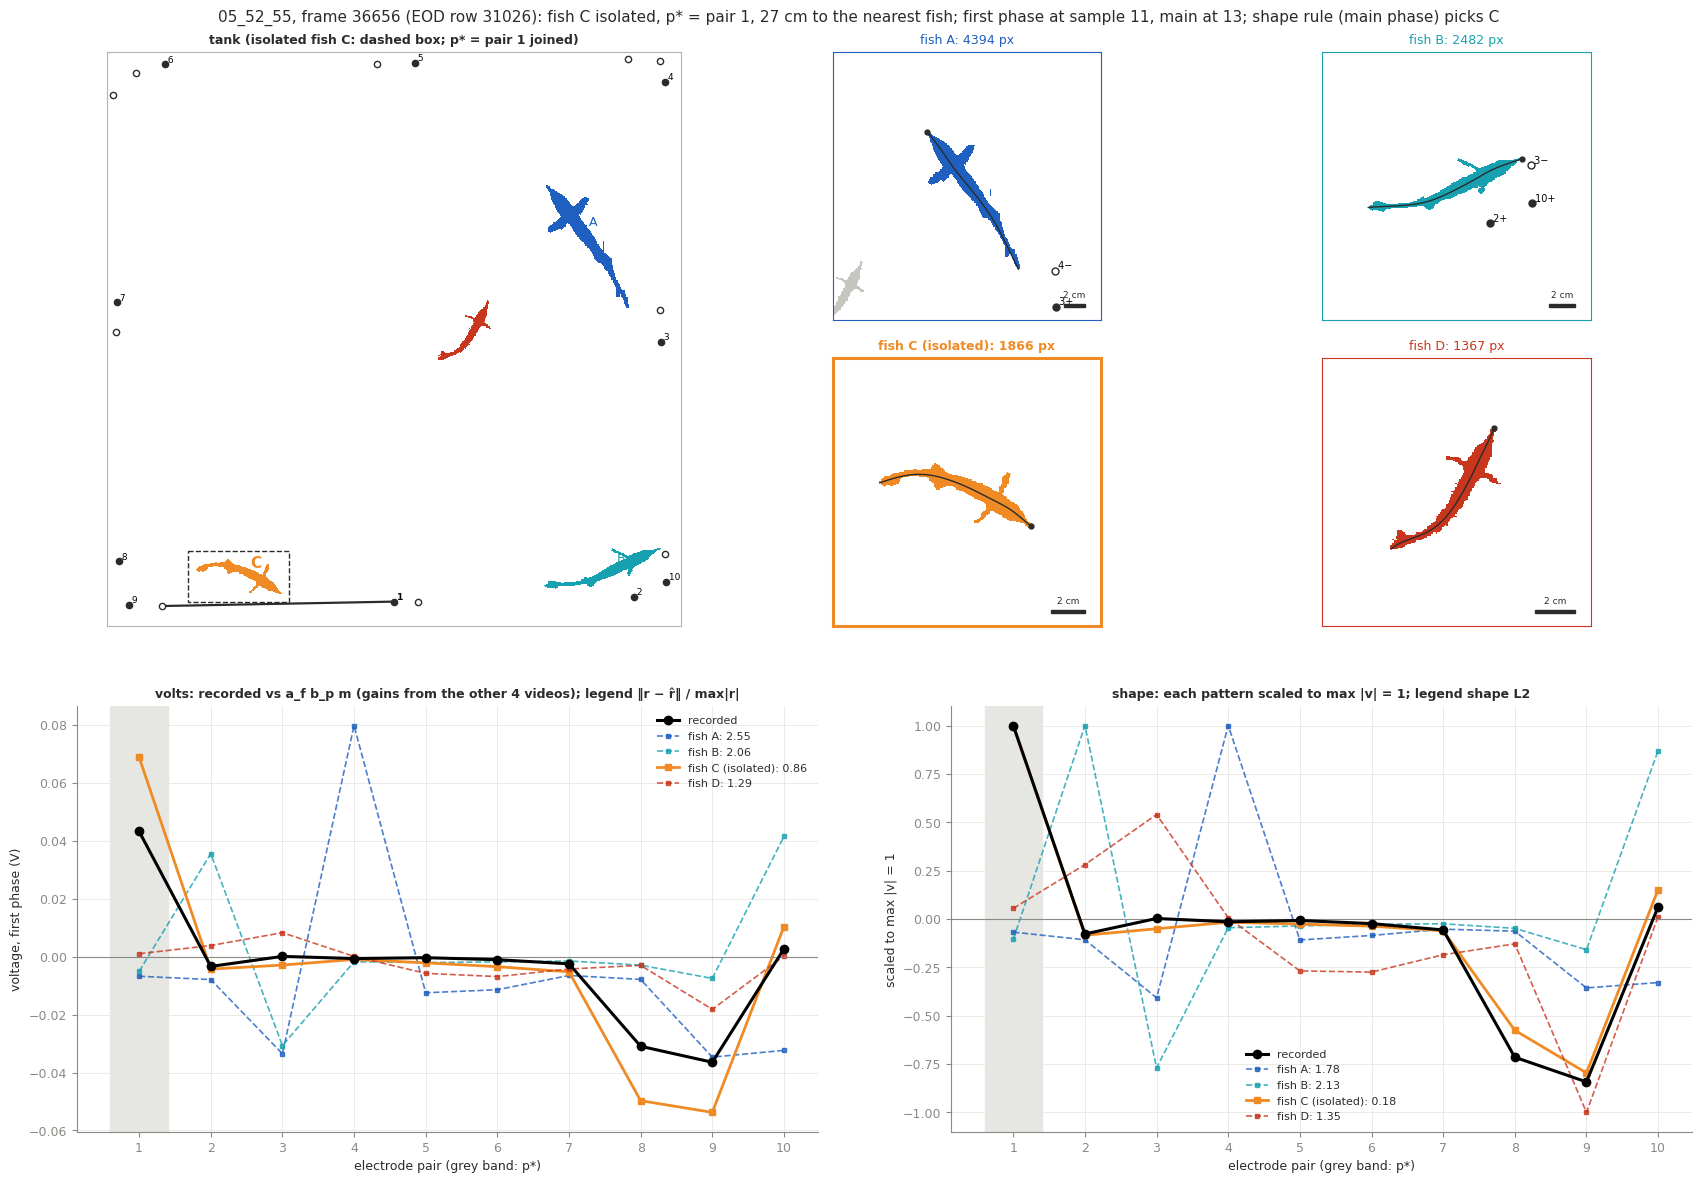

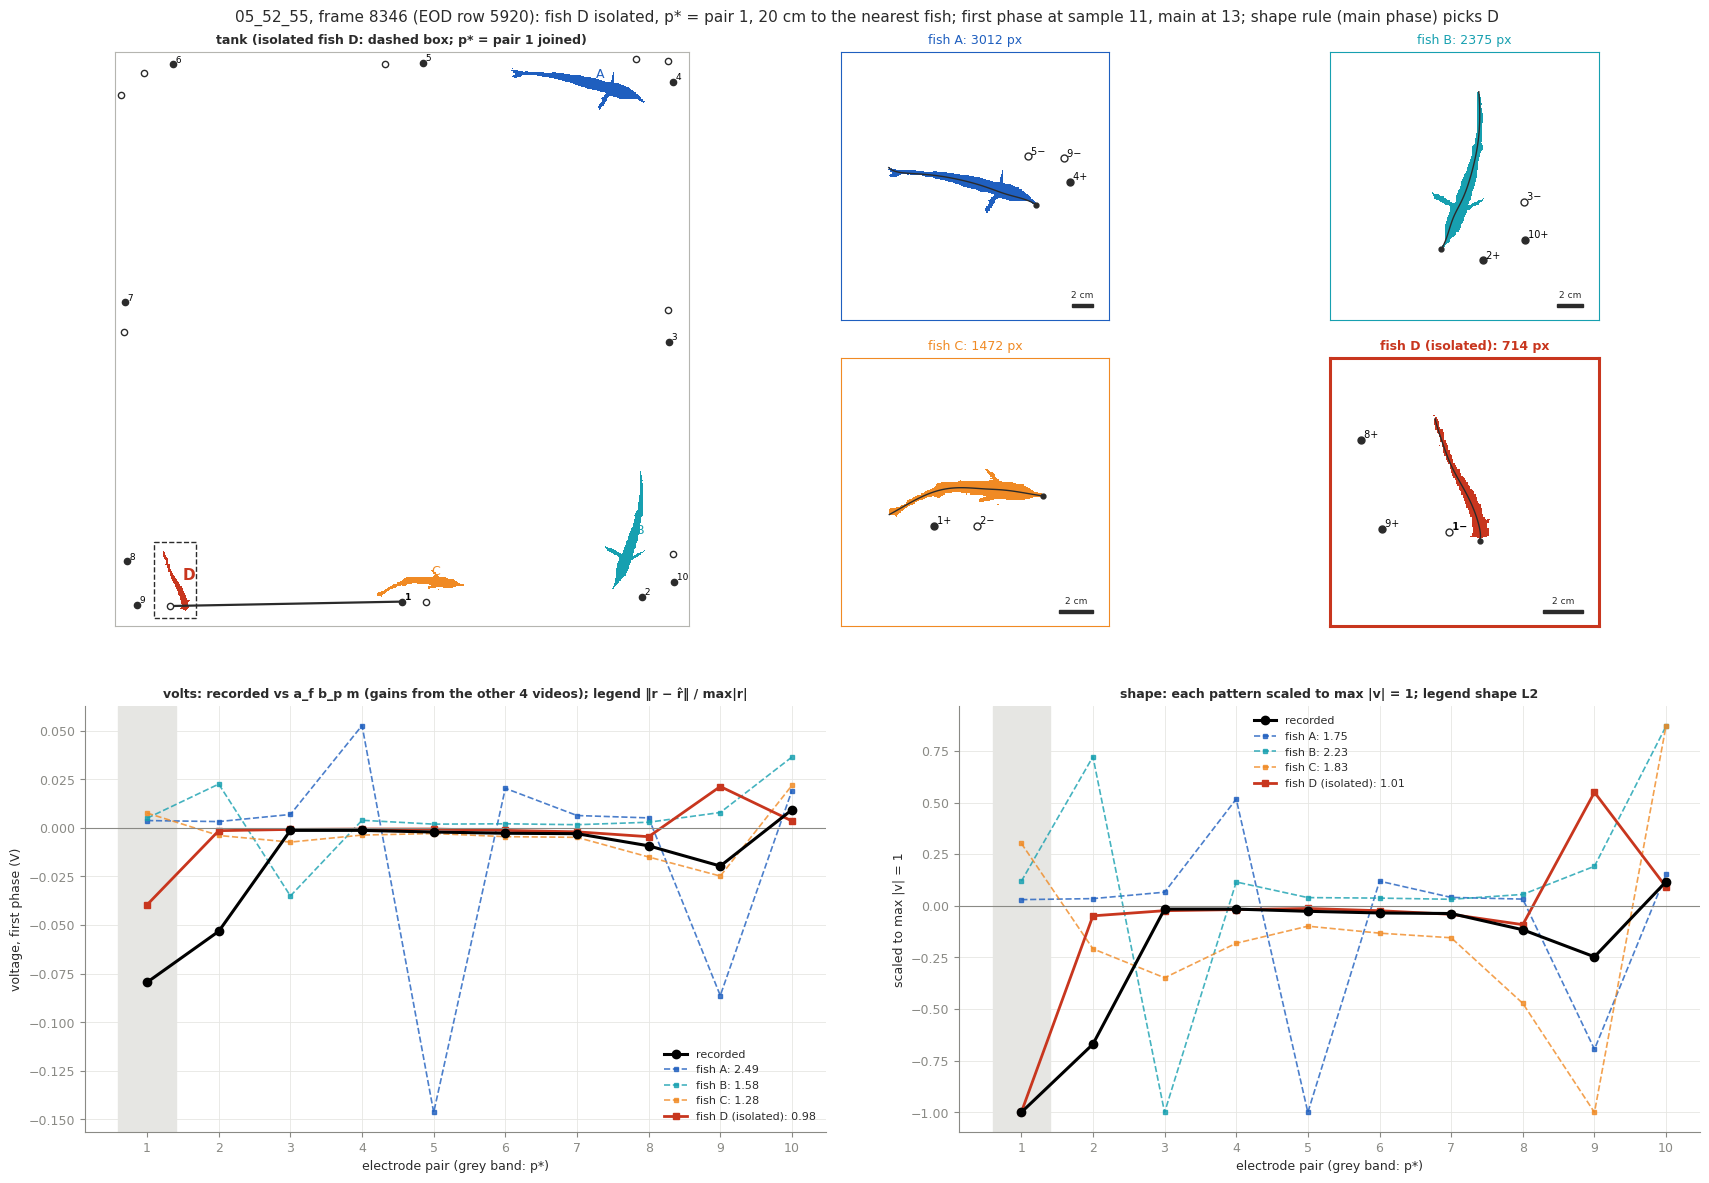

saved 80 PNGs in results/eod_assign_4fish_kaden/fish_pair_factors_iso10cm_dom5/example_frames/per_frame and one PDF per fish in results/eod_assign_4fish_kaden/fish_pair_factors_iso10cm_dom5/example_frames


In [2]:
def draw_electrodes(ax, pstar, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) == pstar
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        color='#000000', fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def tank(ax, r, m):
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET): img[m[j]] = to_rgb(FISH_COL[f])
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for j, f in enumerate(LET):
        if m[j].any():
            yy, xx = np.nonzero(m[j])
            ax.text(xx.mean() + 18, yy.mean() - 18, f, fontsize=11 if f == r.emitter else 9, color=FISH_COL[f],
                    fontweight='bold' if f == r.emitter else 'normal', ha='center', va='center')
    j = LET.index(r.emitter)
    if m[j].any():
        yy, xx = np.nonzero(m[j])
        ax.add_patch(Rectangle((xx.min() - 12, yy.min() - 12), xx.max() - xx.min() + 24, yy.max() - yy.min() + 24,
                               fill=False, ec='#2b2b2b', lw=1, ls='--'))
    draw_electrodes(ax, int(r['pair p* (1-10)']))
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal')
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f"tank (isolated fish {r.emitter}: dashed box; p* = pair {int(r['pair p* (1-10)'])} joined)", fontsize=9)

def zoom(ax, r, m, f, ml):
    j = LET.index(f)
    if not m[j].any():
        ax.axis('off'); ax.text(0.5, 0.5, f'fish {f}: no mask', ha='center', transform=ax.transAxes); return
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean(); h = 0.8 * L_CM[f] * PX_CM
    x0, x1, y0, y1 = cx - h, cx + h, cy - h, cy + h
    img = np.ones((P, P, 3))
    for jj, g in enumerate(LET): img[m[jj]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    if np.isfinite(ml[j]).all():
        ax.plot(ml[j][:, 1], ml[j][:, 0], color='#2b2b2b', lw=1); ax.plot(ml[j][-1, 1], ml[j][-1, 0], 'o', ms=3.5, color='#2b2b2b')
    draw_electrodes(ax, int(r['pair p* (1-10)']) if f == r.emitter else -1, lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.06 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.06 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal')
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == r.emitter else 0.8)
    ax.set_title(f"fish {f}{' (isolated)' if f == r.emitter else ''}: {m[j].sum()} px", fontsize=9,
                 fontweight='bold' if f == r.emitter else 'normal', color=FISH_COL[f])

def voltages(axv, axs, r):
    key = (r.video, int(r.row)); R = R1[key]; Mf = M[key]; pstar = int(r['pair p* (1-10)'])
    a = H.loc[r.video, [f'fish {f}' for f in LET]].to_numpy(float); b = H.loc[r.video, [f'pair {p}' for p in range(1, 11)]].to_numpy(float)
    x = np.arange(1, 11)
    axv.plot(x, R, '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    axs.plot(x, R / np.abs(R).max(), '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    for j, f in enumerate(LET):
        if not np.isfinite(Mf[j]).all(): continue
        iso = f == r.emitter
        pv = a[j] * b * Mf[j]; ev = np.linalg.norm(R - pv) / np.abs(R).max()
        ps = Mf[j] / np.abs(Mf[j]).max(); es = np.linalg.norm(R / np.abs(R).max() - ps)
        kw = dict(color=FISH_COL[f], lw=2 if iso else 1.2, ms=5 if iso else 3.5, alpha=1 if iso else 0.8, ls='-' if iso else '--', marker='s')
        axv.plot(x, pv, label=f'fish {f}{" (isolated)" if iso else ""}: {ev:.2f}', **kw)
        axs.plot(x, ps, label=f'fish {f}{" (isolated)" if iso else ""}: {es:.2f}', **kw)
    for ax, yl, tt in ((axv, 'voltage, first phase (V)', 'volts: recorded vs a_f b_p m (gains from the other 4 videos); legend ‖r − r̂‖ / max|r|'),
                       (axs, 'scaled to max |v| = 1', 'shape: each pattern scaled to max |v| = 1; legend shape L2')):
        ax.axhline(0, color='#8a8a85', lw=0.8); ax.axvspan(pstar - 0.4, pstar + 0.4, color='#e6e6e3', zorder=0)
        ax.set(xticks=x, xlabel='electrode pair (grey band: p*)', ylabel=yl); ax.set_title(tt, fontsize=9)
        ax.legend(fontsize=8, frameon=False, loc='best')

def frame_figure(r):
    key = (r.video, int(r.Frame)); m = masks[key]; ml = mids[key]
    fig = plt.figure(figsize=(17, 12))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], width_ratios=[1.35, 1, 1], hspace=0.16, wspace=0.04, top=0.95, bottom=0.05, left=0.04, right=0.99)
    tank(fig.add_subplot(gs[0, 0]), r, m)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for j, f in enumerate(LET): zoom(fig.add_subplot(gz[j // 2, j % 2]), r, m, f, ml)
    gb = gs[1, :].subgridspec(1, 2, wspace=0.18)
    voltages(fig.add_subplot(gb[0]), fig.add_subplot(gb[1]), r)
    t1, t2 = T1[(r.video, int(r.row))]
    fig.suptitle(f"{r.video}, frame {int(r.Frame)} (EOD row {int(r.row)}): fish {r.emitter} isolated, p* = pair {int(r['pair p* (1-10)'])}, "
                 f"{r['gap (cm)']:.0f} cm to the nearest fish; first phase at sample {t1 + 1}, main at {t2 + 1}; "
                 f"shape rule (main phase) picks {SHAPE_PICK[(r.video, int(r.row))] or '—'}", fontsize=11, y=0.985)
    return fig

for f in LET:
    rows = PK[PK.emitter == f].sort_values(['pair p* (1-10)', 'video']).reset_index(drop=True)
    with PdfPages(f'{EX}/isolated_frame_panels_fish_{f}.pdf') as pdf:
        for k, r in rows.iterrows():
            fig = frame_figure(r)
            fig.savefig(f"{OUT}/fish_{f}_p{int(r['pair p* (1-10)']):02d}_{r.video}_frame{int(r.Frame)}.png", dpi=100, bbox_inches='tight')
            pdf.savefig(fig, bbox_inches='tight')
            if k == 0: plt.show()
            else: plt.close(fig)
print('saved', len(os.listdir(OUT)), 'PNGs in', OUT, 'and one PDF per fish in', EX)